# Online Retail II - Customer & Sales Analysis

Data: [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), all transactions of a UK online gift shop from Dec 2009 to Dec 2011. Many of the customers are wholesalers.

Main question: **Which customers bring the revenue, and how can the business keep them?**

Questions:
1. How is revenue changing over time?
2. When do customers buy (day / hour)?
3. What kind of orders bring the revenue?
4. How much of the revenue comes from the top customers?
5. Which customers are we losing?
6. Do new customers come back?
7. Are international orders different from UK orders?

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format

df = pd.read_csv('DataSet/online_retail_II.csv', encoding_errors='replace')
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. First look at the data

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [3]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


In [4]:
print('Missing Customer ID:', df['Customer ID'].isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Cancelled rows (Invoice starts with C):', df['Invoice'].astype(str).str.startswith('C').sum())
print('Rows with Price <= 0:', (df['Price'] <= 0).sum())

Missing Customer ID: 243007


Duplicate rows: 34335


Cancelled rows (Invoice starts with C): 19494
Rows with Price <= 0: 6207


Notes:
- Quantity and Price have negative values. These are cancellations and adjustments, not sales.
- Around 23% of rows have no Customer ID.

## 3. Cleaning

- Drop duplicate rows.
- Remove cancelled invoices (start with "C").
- Keep only rows where Quantity > 0 and Price > 0.
- Remove codes that are not products (postage, bank charges, manual adjustments...).
- Rows without Customer ID are kept for sales numbers and called "Guest". They are not used in the customer analysis.

In [5]:
df = df.drop_duplicates()
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# can we fill the missing IDs from other rows of the same invoice?
invoices_no_id = set(df[df['Customer ID'].isnull()]['Invoice'])
invoices_with_id = set(df[df['Customer ID'].notnull()]['Invoice'])
print('Invoices that have both:', len(invoices_no_id & invoices_with_id))

Invoices that have both: 0


No invoice has both, so the missing IDs can't be filled.

In [6]:
# cancelled invoices (saved first, we use them in the products part)
cancelled = df[df['Invoice'].str.startswith('C')].copy()
df = df[~df['Invoice'].str.startswith('C')]

# returns, write-offs and free items
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# codes that are not real products
not_products = ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'BANK CHARGES', 'ADJUST', 'ADJUST2',
                'AMAZONFEE', 'PADS', 'CRUK', 'TEST001', 'TEST002', 'B', 'SP1002']
df = df[~df['StockCode'].str.upper().isin(not_products)].copy()

df['Revenue'] = df['Quantity'] * df['Price']
df['Customer Type'] = 'Registered'
df.loc[df['Customer ID'].isnull(), 'Customer Type'] = 'Guest'

# only rows with a Customer ID
customers = df[df['Customer ID'].notnull()].copy()
customers['Customer ID'] = customers['Customer ID'].astype(int)

print('Rows after cleaning:', len(df))
print('Total revenue: £', round(df['Revenue'].sum()))
print('Rows with Customer ID:', len(customers))

Rows after cleaning: 1003415
Total revenue: £ 19645603
Rows with Customer ID: 776577


## 4. Sales

### 4.1 Monthly revenue

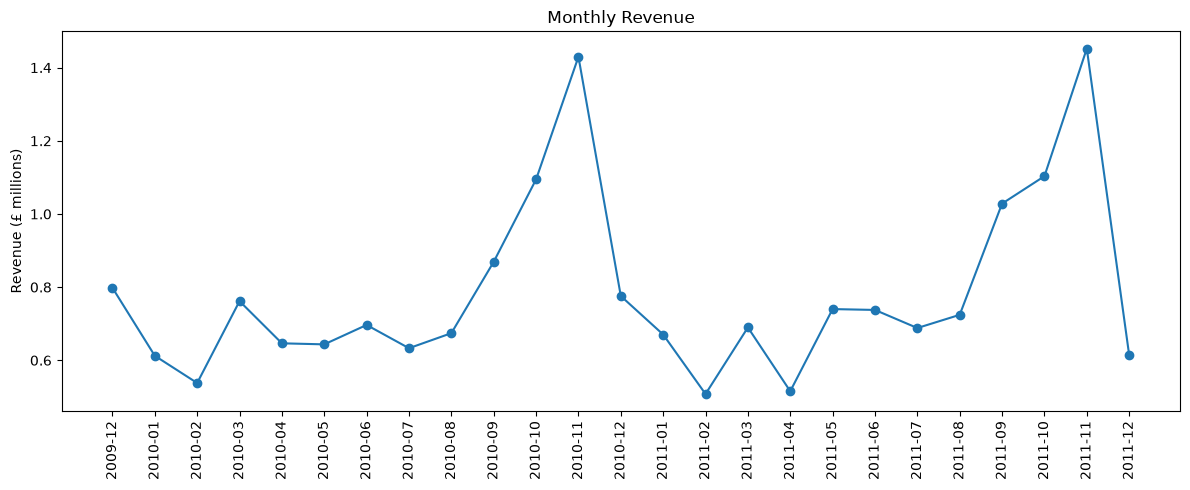

In [7]:
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
monthly = df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values / 1000000, marker='o')
plt.title('Monthly Revenue')
plt.ylabel('Revenue (£ millions)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('images/monthly_revenue.png', dpi=150)
plt.show()

In [8]:
df['Year'] = df['InvoiceDate'].dt.year
df['Month Number'] = df['InvoiceDate'].dt.month

# December 2011 is not complete (data ends on 9 Dec), so compare Jan-Nov only
jan_nov = df[df['Month Number'] <= 11]
rev_2010 = jan_nov[jan_nov['Year'] == 2010]['Revenue'].sum()
rev_2011 = jan_nov[jan_nov['Year'] == 2011]['Revenue'].sum()
growth = (rev_2011 - rev_2010) / rev_2010 * 100

print('Jan-Nov 2010: £', round(rev_2010))
print('Jan-Nov 2011: £', round(rev_2011))
print('Growth:', round(growth, 1), '%')

# how much of 2010 came in Sep, Oct, Nov
year_2010 = df[df['Year'] == 2010]
sep_nov = year_2010[year_2010['Month Number'].isin([9, 10, 11])]['Revenue'].sum()
print('Sep-Nov share of 2010:', round(sep_nov / year_2010['Revenue'].sum() * 100), '%')

Jan-Nov 2010: £ 8599579
Jan-Nov 2011: £ 8857691
Growth: 3.0 %
Sep-Nov share of 2010: 36 %


**Insight:** Revenue barely grew (+3% from 2010 to 2011), but it is very seasonal. 36% of 2010 revenue came in only three months (Sep-Nov), when shops stock up for Christmas. Stock, staff and marketing should be ready before September.

### 4.2 When do customers buy?

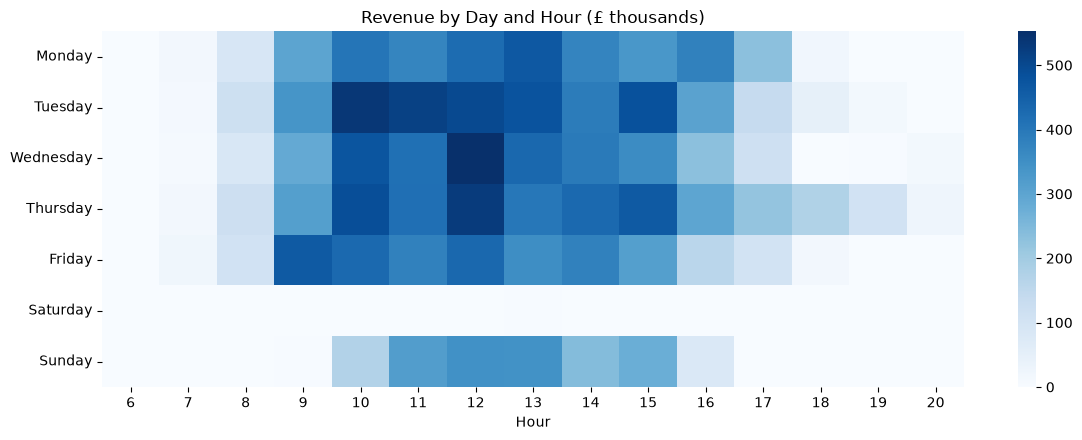

In [9]:
df['Day'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat = df.pivot_table(index='Day', columns='Hour', values='Revenue', aggfunc='sum')
heat = heat.reindex(days).fillna(0)

plt.figure(figsize=(12, 4.5))
sns.heatmap(heat / 1000, cmap='Blues')
plt.title('Revenue by Day and Hour (£ thousands)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('images/day_hour_heatmap.png', dpi=150)
plt.show()

In [10]:
by_hour = df.groupby('Hour')['Revenue'].sum()
office_hours = by_hour.loc[10:15].sum()
print('Revenue between 10:00 and 15:59:', round(office_hours / by_hour.sum() * 100), '%')

Revenue between 10:00 and 15:59: 75 %


**Insight:** About 75% of revenue comes between 10:00 and 16:00, and there are almost no sales on Saturday. Customers buy like businesses, during office hours. Emails, offers and customer service should focus on weekday working hours.

### 4.3 Order size

In [11]:
orders = df.groupby('Invoice').agg(
    Revenue=('Revenue', 'sum'),
    Country=('Country', 'first')
).reset_index()

orders['Order Size'] = pd.cut(orders['Revenue'],
                              bins=[0, 100, 300, 1000, float('inf')],
                              labels=['Small (<£100)', 'Medium (£100-300)', 'Large (£300-1k)', 'Wholesale (>£1k)'])

summary = orders.groupby('Order Size', observed=True).agg(Orders=('Invoice', 'count'), Revenue=('Revenue', 'sum'))
summary['Orders %'] = summary['Orders'] / summary['Orders'].sum() * 100
summary['Revenue %'] = summary['Revenue'] / summary['Revenue'].sum() * 100
summary

,Orders,Revenue,Orders %,Revenue %
Order Size,,,,
Small (<£100),5637,"239,533.23",14.27,1.22
Medium (£100-300),13931,"2,652,935.08",35.25,13.50
Large (£300-1k),16535,"8,041,477.85",41.84,40.93
Wholesale (>£1k),3413,"8,711,656.88",8.64,44.34


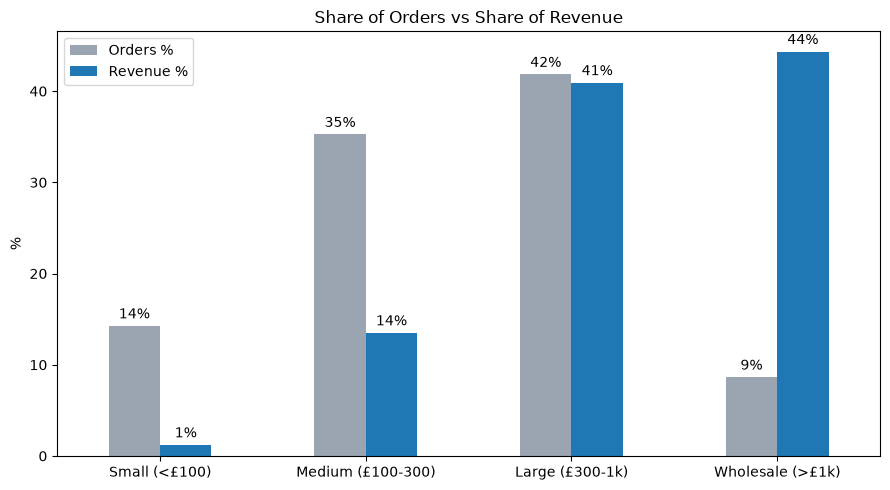

In [12]:
ax = summary[['Orders %', 'Revenue %']].plot(kind='bar', figsize=(9, 5), color=['#9aa5b1', '#1f77b4'])

# show the % on each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', padding=3)

plt.title('Share of Orders vs Share of Revenue')
plt.ylabel('%')
plt.xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('images/order_size_share.png', dpi=150)
plt.show()

**Insight:** Only 9% of orders are above £1,000, but they bring 44% of the revenue. Small orders are 14% of orders and bring just 1%. Losing a few big buyers hurts much more than losing many small ones.

### 4.4 Which products bring the most money, and which bring the least?

The data has no product cost, so we look at sales instead of profit.
Cancelled orders are subtracted, because some big orders were cancelled right after they were placed
(for example, one order of 80,995 pieces of "PAPER CRAFT , LITTLE BIRDIE").

In [13]:
cancelled['Revenue'] = cancelled['Quantity'] * cancelled['Price']   # negative values

product_sales = df.groupby('Description')['Revenue'].sum()
product_cancelled = cancelled.groupby('Description')['Revenue'].sum()

products = pd.DataFrame({'Sales': product_sales})
products['Cancelled'] = product_cancelled
products['Cancelled'] = products['Cancelled'].fillna(0)
products['Net Sales'] = products['Sales'] + products['Cancelled']
products = products.sort_values('Net Sales', ascending=False)

print('Number of products:', len(products))

Number of products: 5383


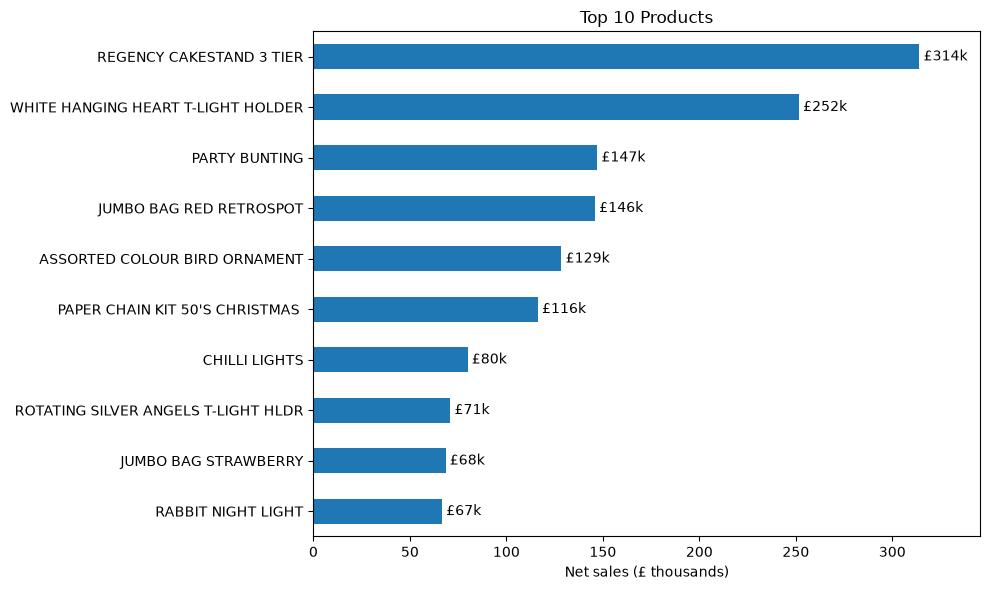

In [14]:
top10 = products.head(10)

ax = (top10['Net Sales'] / 1000).plot(kind='barh', figsize=(10, 6), color='#1f77b4')
ax.bar_label(ax.containers[0], fmt='£%.0fk', padding=3)
ax.margins(x=0.1)
plt.title('Top 10 Products')
plt.xlabel('Net sales (£ thousands)')
plt.ylabel('')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('images/top_products.png', dpi=150)
plt.show()

In [15]:
# products that sold the least (but still sold something)
low = products[products['Net Sales'] > 0].tail(10)
low

,Sales,Cancelled,Net Sales
Description,,,
RED TOP SCANDINAVIAN HEART,1.52,0.00,1.52
FOLKART HEART CHRISTMAS DECORATIONS,1.25,0.00,1.25
SET 36 COLOURING PENCILS DOILEY,1.25,0.00,1.25
HOLLYHOCK SQUARE HANDY TIN,1.25,0.00,1.25
CAT WITH SUNGLASSES BLANK CARD,0.95,0.00,0.95
OWLS CHARLOTTE BAG,0.85,0.00,0.85
CAT W SUNGLASSES BLANK CARD,0.76,0.00,0.76
SET 12 COLOURING PENCILS DOILEY,0.65,0.00,0.65
PINK HEART CHRISTMAS DECORATION,0.38,0.00,0.38


In [16]:
n = len(products)
total = products['Net Sales'].sum()

print('Top 20% of products:', round(products.head(int(n * 0.2))['Net Sales'].sum() / total * 100), '% of sales')
print('Bottom 50% of products:', round(products.tail(n // 2)['Net Sales'].sum() / total * 100), '% of sales')
print('Products with less than £100 in 2 years:', (products['Net Sales'] < 100).sum())

Top 20% of products: 78 % of sales
Bottom 50% of products: 4 % of sales
Products with less than £100 in 2 years: 889


**Insight:** The best seller is the **Regency Cakestand 3 Tier** (£314k), then the **White Hanging Heart T-Light Holder** (£252k) and **Party Bunting** (£147k). Most top products are home decoration, party and Christmas items, which fits the Sep-Nov peak.

On the other side, most products sell very little: the bottom half of the products bring only 4% of sales, and 889 products made less than £100 in two years. The shop should always keep the top products in stock and review the slow ones.

### 4.5 Which products are inside the Wholesale orders (>£1k)?

Wholesale orders are 9% of all orders but bring 44% of revenue. Which products do they buy?

In [17]:
wholesale_orders = orders[orders['Order Size'] == 'Wholesale (>£1k)']['Invoice']

# orders that were cancelled right after they were placed:
# 80,995 paper crafts, 74,215 storage jars, and a £38,970 picnic basket order reversed by a manual credit
wholesale_orders = wholesale_orders[~wholesale_orders.isin(['581483', '541431', '556444'])]

wholesale = df[df['Invoice'].isin(wholesale_orders)]

top_wholesale = wholesale.groupby('Description').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique')
).sort_values('Revenue', ascending=False).head(10)

top_wholesale['% of Wholesale Revenue'] = top_wholesale['Revenue'] / wholesale['Revenue'].sum() * 100
top_wholesale['% of Wholesale Orders'] = top_wholesale['Orders'] / len(wholesale_orders) * 100

print('Wholesale orders:', len(wholesale_orders))
top_wholesale

Wholesale orders: 3410


,Revenue,Orders,% of Wholesale Revenue,% of Wholesale Orders
Description,,,,
REGENCY CAKESTAND 3 TIER,"165,770.41",949,1.97,27.83
WHITE HANGING HEART T-LIGHT HOLDER,"102,908.19",904,1.22,26.51
JUMBO BAG RED RETROSPOT,"70,770.89",797,0.84,23.37
PAPER CHAIN KIT 50'S CHRISTMAS,"69,167.52",487,0.82,14.28
PARTY BUNTING,"66,847.23",680,0.79,19.94
ROTATING SILVER ANGELS T-LIGHT HLDR,"55,023.67",265,0.65,7.77
ASSORTED COLOUR BIRD ORNAMENT,"47,861.51",408,0.57,11.96
CHILLI LIGHTS,"38,406.03",340,0.46,9.97
RABBIT NIGHT LIGHT,"38,119.56",217,0.45,6.36


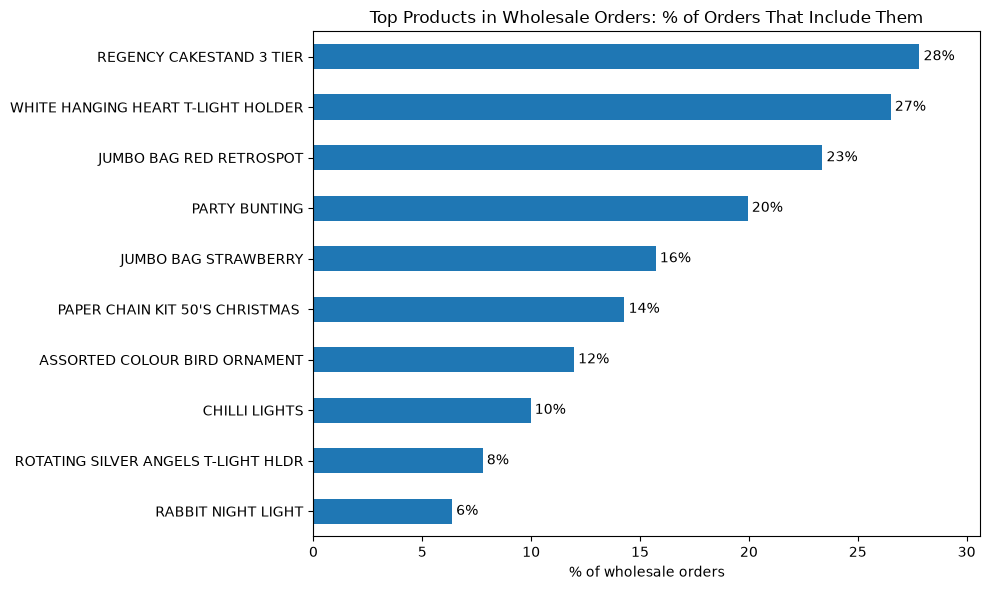

Top 10 products together: 8 % of wholesale revenue


In [18]:
by_orders = top_wholesale.sort_values('% of Wholesale Orders', ascending=False)
ax = by_orders['% of Wholesale Orders'].plot(kind='barh', figsize=(10, 6), color='#1f77b4')
ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=3)
ax.margins(x=0.1)
plt.title('Top Products in Wholesale Orders: % of Orders That Include Them')
plt.xlabel('% of wholesale orders')
plt.ylabel('')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('images/wholesale_products.png', dpi=150)
plt.show()

print('Top 10 products together:', round(top_wholesale['% of Wholesale Revenue'].sum()), '% of wholesale revenue')

**Insight:** No single product carries the Wholesale orders. The top product, the **Regency Cakestand 3 Tier**, brings only about **2% of wholesale revenue**, but it is in **28% of these orders** (949 out of 3,410). The White Hanging Heart T-Light Holder (27%) and Jumbo Bag Red Retrospot (23%) come next. Even the top 10 products together bring only 8% of wholesale revenue.

So big buyers fill their orders with many different products. The top products are the "must-have" items that show up in many big orders, so they should never be out of stock.

## 5. Customers

### 5.1 How much do the top customers bring?

In [19]:
customer_revenue = customers.groupby('Customer ID')['Revenue'].sum().sort_values(ascending=False)
n = len(customer_revenue)
total = customer_revenue.sum()

top_20 = customer_revenue.head(int(n * 0.20)).sum() / total * 100
top_1 = customer_revenue.head(int(n * 0.01)).sum() / total * 100
guest = df[df['Customer Type'] == 'Guest']['Revenue'].sum() / df['Revenue'].sum() * 100

print('Customers:', n)
print('Top 20% of customers:', round(top_20), '% of revenue')
print('Top 1% of customers:', round(top_1), '% of revenue')
print('Guest orders:', round(guest), '% of total revenue')

Customers: 5852
Top 20% of customers: 77 % of revenue
Top 1% of customers: 32 % of revenue
Guest orders: 13 % of total revenue


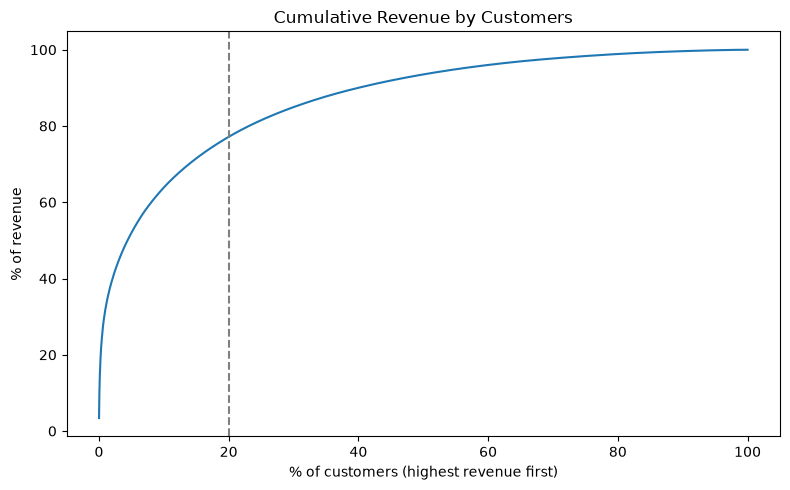

In [20]:
cumulative = customer_revenue.cumsum() / total * 100
customer_pct = [i / n * 100 for i in range(1, n + 1)]

plt.figure(figsize=(8, 5))
plt.plot(customer_pct, cumulative.values)
plt.axvline(20, color='gray', linestyle='--')
plt.title('Cumulative Revenue by Customers')
plt.xlabel('% of customers (highest revenue first)')
plt.ylabel('% of revenue')
plt.tight_layout()
plt.savefig('images/pareto_customers.png', dpi=150)
plt.show()

**Insight:** The top 20% of customers bring 77% of revenue, and the top 1% alone bring 32%. A few big accounts carry the business. Also, 13% of all revenue comes from Guest orders, so the business can't follow up with those buyers.

### 5.2 Customer groups

Each customer is put in a group based on two simple things:
- How many days since their last order (counted from the last date in the data, 9 Dec 2011)
- How many orders they made

| Group | Rule |
|---|---|
| Loyal | ordered in the last 90 days, 5+ orders |
| Active | ordered in the last 90 days, less than 5 orders |
| At Risk | last order 91-365 days ago, 5+ orders |
| Cooling Down | last order 91-365 days ago, less than 5 orders |
| Lost | no order for more than a year |

In [21]:
last_date = df['InvoiceDate'].max()

cust = customers.groupby('Customer ID').agg(
    Last_Order=('InvoiceDate', 'max'),
    Orders=('Invoice', 'nunique'),
    Revenue=('Revenue', 'sum')
)
cust['Days Since Last Order'] = (last_date - cust['Last_Order']).dt.days


def get_group(row):
    days = row['Days Since Last Order']
    if days <= 90:
        if row['Orders'] >= 5:
            return 'Loyal'
        return 'Active'
    if days <= 365:
        if row['Orders'] >= 5:
            return 'At Risk'
        return 'Cooling Down'
    return 'Lost'


cust['Group'] = cust.apply(get_group, axis=1)
cust.head()

,Last_Order,Orders,Revenue,Days Since Last Order,Group
Customer ID,,,,,
12346,2011-01-18 10:01:00,3,"77,352.96",325,Cooling Down
12347,2011-12-07 15:52:00,8,"4,921.53",1,Loyal
12348,2011-09-25 13:13:00,5,"1,658.40",74,Loyal
12349,2011-11-21 09:51:00,3,"3,678.69",18,Active
12350,2011-02-02 16:01:00,1,294.40,309,Cooling Down


In [22]:
groups = cust.groupby('Group').agg(
    Customers=('Orders', 'count'),
    Revenue=('Revenue', 'sum'),
    Avg_Orders=('Orders', 'mean'),
    Avg_Days_Since_Last_Order=('Days Since Last Order', 'mean')
).sort_values('Revenue', ascending=False)

groups['Customers %'] = groups['Customers'] / groups['Customers'].sum() * 100
groups['Revenue %'] = groups['Revenue'] / groups['Revenue'].sum() * 100
groups

,Customers,Revenue,Avg_Orders,Avg_Days_Since_Last_Order,Customers %,Revenue %
Group,,,,,,
Loyal,1614,"12,550,097.32",15.24,25.93,27.58,73.53
At Risk,405,"1,247,873.06",8.48,182.50,6.92,7.31
Active,1275,"1,222,373.04",2.35,37.17,21.79,7.16
Lost,1575,"1,207,089.27",2.20,501.19,26.91,7.07
Cooling Down,983,"841,135.28",2.14,216.87,16.80,4.93


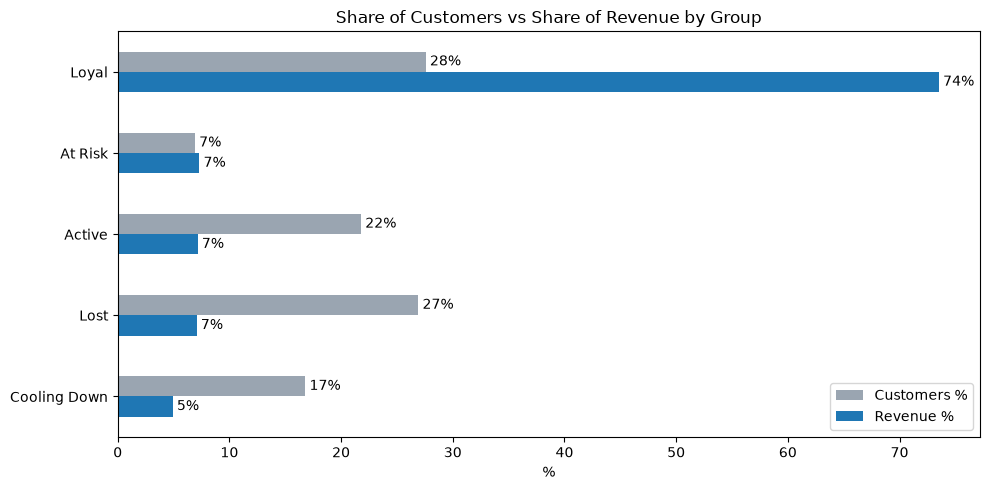

Customers who bought only once: 28 %


In [23]:
ax = groups[['Customers %', 'Revenue %']].plot(kind='barh', figsize=(10, 5), color=['#9aa5b1', '#1f77b4'])

# show the % on each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', padding=3)

plt.title('Share of Customers vs Share of Revenue by Group')
plt.xlabel('%')
plt.ylabel('')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('images/customer_groups.png', dpi=150)
plt.show()

one_time = (cust['Orders'] == 1).sum() / len(cust) * 100
print('Customers who bought only once:', round(one_time), '%')

**Insight:** Loyal customers are 28% of customers but bring 74% of revenue. The group to act on is **At Risk**: 405 customers who used to order often (about 8 orders each) but stopped about 6 months ago. Together they spent about £1.25M. They already know the shop, so getting them back is cheaper than finding new customers. Also, 28% of customers bought only once.

### 5.3 Do new customers come back?

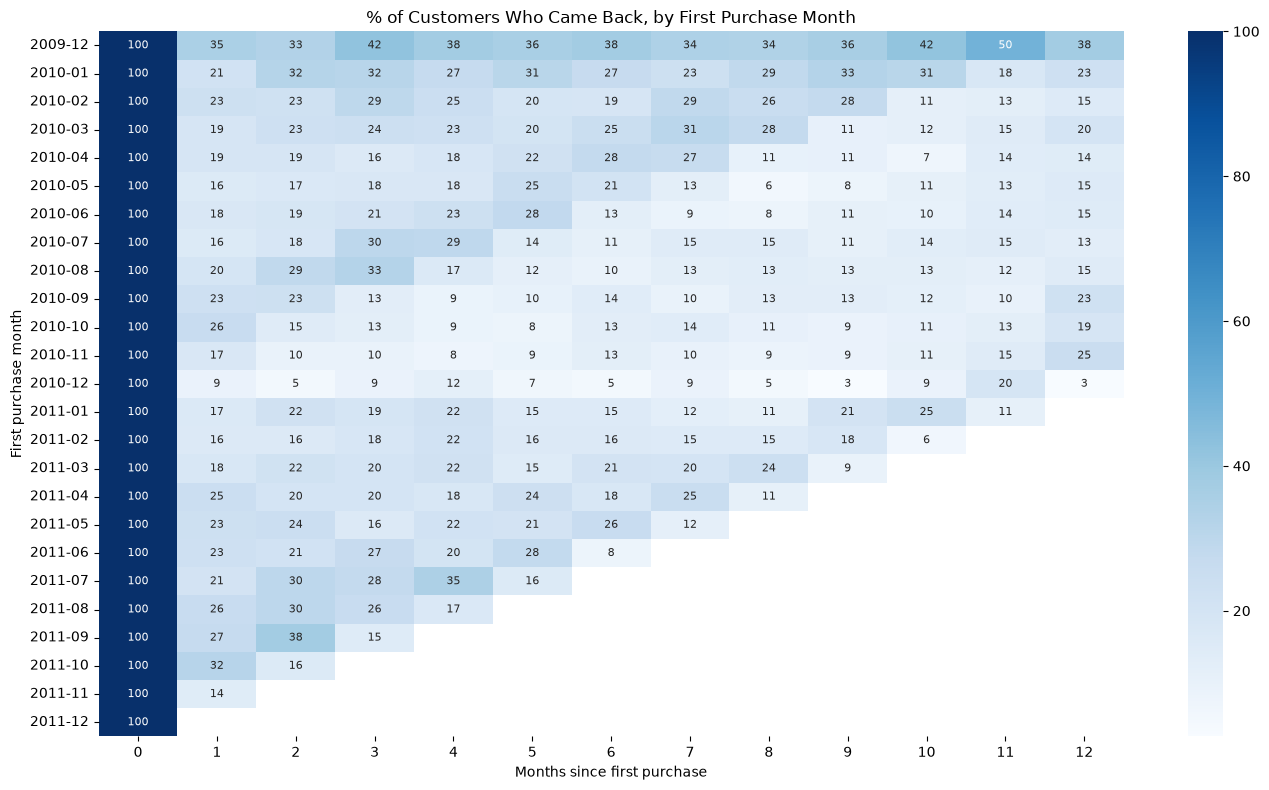

In [24]:
customers['Order Month'] = customers['InvoiceDate'].dt.to_period('M')
first_month = customers.groupby('Customer ID')['Order Month'].min()
customers['First Month'] = customers['Customer ID'].map(first_month)

# months between the first order and this order
customers['Months Later'] = ((customers['Order Month'].dt.year - customers['First Month'].dt.year) * 12
                             + (customers['Order Month'].dt.month - customers['First Month'].dt.month))

cohort = customers.pivot_table(index='First Month', columns='Months Later',
                               values='Customer ID', aggfunc='nunique')
retention = cohort.divide(cohort[0], axis=0) * 100

plt.figure(figsize=(14, 8))
sns.heatmap(retention.iloc[:, :13], annot=True, fmt='.0f', cmap='Blues', annot_kws={'size': 8})
plt.title('% of Customers Who Came Back, by First Purchase Month')
plt.xlabel('Months since first purchase')
plt.ylabel('First purchase month')
plt.tight_layout()
plt.savefig('images/cohort_retention.png', dpi=150)
plt.show()

In [25]:
# Dec 2009 is the first month of the data, so it has old customers too, not only new ones.
new_customers = retention.iloc[1:]
print('Average % coming back:')
print('after 1 month:  ', round(new_customers[1].mean()), '%')
print('after 3 months: ', round(new_customers[3].mean()), '%')
print('after 6 months: ', round(new_customers[6].mean()), '%')
print('after 12 months:', round(new_customers[12].mean()), '%')

Average % coming back:
after 1 month:   20 %
after 3 months:  21 %
after 6 months:  17 %
after 12 months: 17 %


**Insight:** Only about 1 in 5 new customers come back in any later month, and this doesn't get better over time. The Dec 2009 row looks much higher because the data starts then, so it includes old loyal customers. The weak point is the second order: a follow-up or a discount on the second order is the easiest thing to try.

## 6. UK vs international orders

In [26]:
orders['Region'] = 'International'
orders.loc[orders['Country'] == 'United Kingdom', 'Region'] = 'UK'

orders.groupby('Region')['Revenue'].agg(['count', 'median', 'mean'])

,count,median,mean
Region,,,
International,3332,421.37,853.19
UK,36184,295.09,464.37


**Insight:** A typical international order is about £421, while a typical UK order is about £295 (about 43% bigger). International customers order less often but buy more each time, so they are a good place to grow.

## 7. Summary

### What we found
1. Revenue is flat (+3%) but very seasonal: 36% of the year's revenue comes in Sep-Nov.
2. Customers buy during office hours on weekdays (75% between 10:00 and 16:00), and almost never on Saturday.
3. 9% of orders (over £1,000) bring 44% of revenue.
4. The top 20% of customers bring 77% of revenue; the top 1% bring 32%.
5. 405 At Risk customers (about £1.25M in past revenue) have stopped ordering.
6. Only about 1 in 5 new customers come back, and 28% bought only once.
7. International orders are bigger than UK orders (£421 vs £295 typical order).
8. The top 20% of products bring 78% of sales, while the bottom half bring only 4%.
9. The top product (Regency Cakestand) is in 28% of Wholesale orders, but no single product brings more than 2% of their revenue.

### What to do
1. **Win back At Risk customers** before the Sep-Nov peak with a direct offer.
2. **Get the second order.** Follow up with new customers in their first 30 days and give a reason to buy again. Use the table above to check if it works.
3. **Look after big accounts.** Give the top 1% a dedicated contact, and ask Guest buyers (13% of revenue) to create an account.
4. **Keep the best-selling products in stock** before September, and review the products that almost never sell.

### Limits
- Customer analysis only uses orders with a Customer ID (about 77% of rows).
- December 2011 is not complete.
- The customer group rules (90 days, 5 orders) are simple choices, other cut-offs would give slightly different numbers.